In [1]:
import pandas as pd 
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import CountVectorizer

In [2]:
df=pd.read_csv("email.csv")
df.head()

,text,spam
0,Subject: naturally irresistible your corporate...,1
1,Subject: the stock trading gunslinger fanny i...,1
2,Subject: unbelievable new homes made easy im ...,1
3,Subject: 4 color printing special request add...,1
4,"Subject: do not have money , get software cds ...",1


In [3]:
x=df['text']
y=df['spam']

In [4]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42
)

In [5]:
vect=CountVectorizer()
x_train=vect.fit_transform(x_train)
x_test=vect.transform(x_test)

In [6]:
model=MultinomialNB()
model.fit(x_train,y_train)

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [7]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
y_pred=model.predict(x_test)
accuracy_score(y_test,y_pred)

0.987783595113438

In [8]:
cm=confusion_matrix(y_test,y_pred)
cm

array([[850,   6],
       [  8, 282]])

<Axes: >

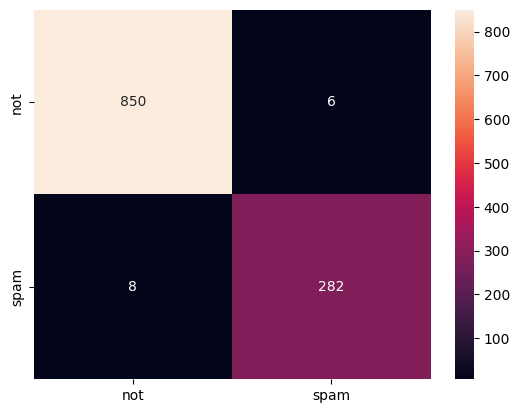

In [9]:
import seaborn as sns 
import matplotlib.pyplot as plt
sns.heatmap(cm,annot=True,fmt='d',xticklabels=['not','spam'],yticklabels=['not','spam'])

In [15]:
email = input("Enter email: ")

email_vector = vect.transform([email])

prediction = model.predict(email_vector)

if prediction[0] == 1:
    print("Spam")
else:
    print("Not Spam")

Not Spam
